# Taller 10: Redes Neuronales Artificiales — clasificación de dígitos



## 1. Librerías

In [25]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             cohen_kappa_score, log_loss, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

SEMILLA = 42
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("Versiones: NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Versiones: NumPy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1


Forma de X: (1797, 64) | Forma de y: (1797,)
Rango de píxeles: 0.0 a 16.0

 Dígito  Cantidad
      0       178
      1       182
      2       177
      3       183
      4       181
      5       182
      6       181
      7       179
      8       174
      9       180


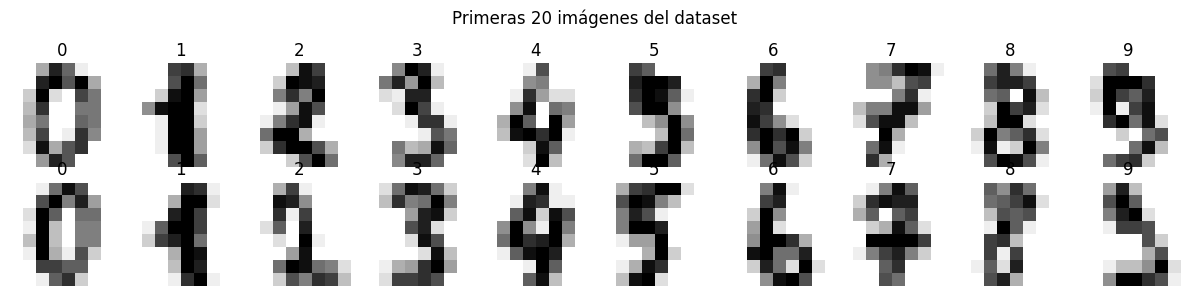

In [26]:
digits = load_digits()
X, y = digits.data, digits.target
print("Forma de X:", X.shape, "| Forma de y:", y.shape)
print("Rango de píxeles:", X.min(), "a", X.max())
print()
print(pd.DataFrame({"Dígito": range(10), "Cantidad": np.bincount(y)}).to_string(index=False))

fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(digits.target[i])
    ax.axis("off")
plt.suptitle("Primeras 20 imágenes del dataset")
plt.tight_layout()
plt.show()

## 3. Entrenamiento, validación y prueba
Particiones **estratificadas** (cada dígito conserva su proporción): 60 % entrenamiento, 20 % validación y 20 % prueba.

- **Entrenamiento:** ajusta los pesos.
- **Validación:** sirve para comparar y elegir la activación.
- **Prueba:** se usa **una sola vez**, al final, con el modelo ya elegido. Así la estimación del desempeño no queda contaminada por la selección.

In [27]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEMILLA)

print(pd.DataFrame({"Partición": ["Entrenamiento", "Validación", "Prueba"],
                    "Muestras": [len(y_train), len(y_val), len(y_test)]}).to_string(index=False))

    Partición  Muestras
Entrenamiento      1077
   Validación       360
       Prueba       360


## 4. Las cuatro funciones de activación
Una neurona calcula $z=\mathbf{w}\cdot\mathbf{x}+b$ y luego aplica una función de activación $f(z)$. Sin activaciones no lineales, apilar capas no aporta nada. Las cuatro del ejemplo:

**`identity`** — $f(z)=z$
No transforma la señal. Con ella, toda la red es una composición de transformaciones lineales, equivalente a **una sola transformación lineal**, sin importar cuántas neuronas ocultas haya. Solo puede aprender fronteras de decisión lineales (es básicamente una regresión logística multinomial). Es la más barata de calcular, pero la menos expresiva.

**`logistic`** (sigmoide) — $f(z)=\dfrac{1}{1+e^{-z}}$
Comprime cualquier valor al intervalo $(0,1)$. Es suave y diferenciable. Su problema es la **saturación**: para $|z|$ grande la pendiente tiende a 0, el gradiente se desvanece y el aprendizaje se vuelve lento. Además, su salida no está centrada en cero.

**`tanh`** (tangente hiperbólica) — $f(z)=\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$
Comprime al intervalo $(-1,1)$ y está **centrada en cero**, lo que suele facilitar la optimización respecto a la sigmoide. También satura para $|z|$ grande, aunque su pendiente máxima (1 en $z=0$) es mayor que la de la sigmoide (0,25).

**`relu`** (unidad lineal rectificada) — $f(z)=\max(0,z)$
Vale 0 para entradas negativas y deja pasar las positivas. Es muy barata de calcular, no satura en la zona positiva (gradiente constante igual a 1) y produce activaciones dispersas. Su riesgo son las *neuronas muertas* (si $z<0$ siempre, su gradiente es 0) y que no es diferenciable en $z=0$.

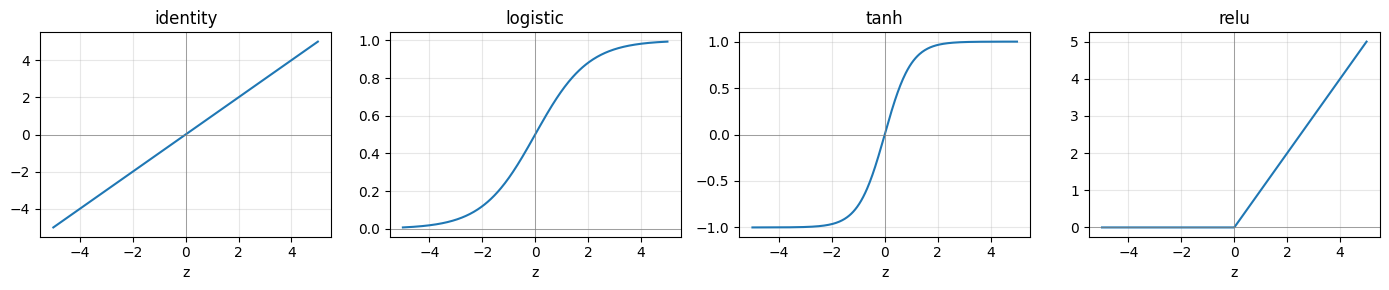

In [28]:
z = np.linspace(-5, 5, 400)
funciones = {
    "identity": z,
    "logistic": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "relu": np.maximum(0, z),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (nombre, f) in zip(axes, funciones.items()):
    ax.plot(z, f)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(nombre); ax.set_xlabel("z"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Modelo y métricas
**Arquitectura:** 64 entradas → **1 capa oculta de 50 neuronas** → 10 salidas (softmax, una por dígito). La activación elegida solo afecta la capa oculta.

**Solver L-BFGS** (método cuasi-Newton): usa todo el conjunto de entrenamiento en cada paso, sin minilotes, y converge rápido en conjuntos pequeños como este.

**Escalado:** `StandardScaler` dentro del `Pipeline`, de modo que se ajusta únicamente con los datos de entrenamiento (evita filtración de información hacia validación y prueba).

**Métricas**:
- **Accuracy:** proporción de aciertos.
- **Balanced accuracy:** promedio del recall de cada clase.
- **F1 macro:** promedio del F1 de las 10 clases.
- **Kappa:** acuerdo corregido por el azar.
- **Log loss:** calidad de las probabilidades; penaliza fuerte los errores muy seguros (menor es mejor).

In [29]:
def evaluar(modelo, entradas, etiquetas):
    pred = modelo.predict(entradas)
    prob = modelo.predict_proba(entradas)
    return {
        "Accuracy": accuracy_score(etiquetas, pred),
        "Balanced accuracy": balanced_accuracy_score(etiquetas, pred),
        "F1 macro": f1_score(etiquetas, pred, average="macro"),
        "Kappa": cohen_kappa_score(etiquetas, pred),
        "Log loss": log_loss(etiquetas, prob, labels=modelo.classes_),
    }

def construir_mlp(activacion, semilla=SEMILLA):
    return Pipeline([
        ("escala", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(50,), activation=activacion,
                              solver="lbfgs", alpha=1e-4, tol=1e-6,
                              max_iter=2000, random_state=semilla)),
    ])

## 6. Referencia mínima
Un clasificador que siempre predice la clase más frecuente sirve de piso: cualquier MLP razonable debe superarlo por mucho.

In [30]:
referencia = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Referencia en validación:")
print(pd.Series(evaluar(referencia, X_val, y_val)).round(4).to_string())

Referencia en validación:
Accuracy              0.1028
Balanced accuracy     0.1000
F1 macro              0.0186
Kappa                 0.0000
Log loss             32.3392


## 7. Comparación controlada en validación
Se entrena un MLP por activación, registrando métricas en entrenamiento y validación, **número de iteraciones**, **tiempo de entrenamiento** y si hubo advertencias de convergencia.

In [31]:
modelos, filas, avisos_por_modelo = {}, [], {}
for activacion in ["identity", "logistic", "tanh", "relu"]:
    modelo = construir_mlp(activacion)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_train, y_train)
    segundos = time.perf_counter() - inicio
    mensajes = [str(a.message) for a in avisos if issubclass(a.category, ConvergenceWarning)]

    tr = evaluar(modelo, X_train, y_train)
    va = evaluar(modelo, X_val, y_val)
    filas.append({"Activación": activacion,
                  "Accuracy train": tr["Accuracy"],
                  **va,
                  "Iteraciones": modelo.named_steps["mlp"].n_iter_,
                  "Aviso convergencia": bool(mensajes),
                  "Segundos": segundos})
    modelos[activacion] = modelo
    avisos_por_modelo[activacion] = mensajes

resultados = pd.DataFrame(filas).set_index("Activación")
print("Métricas de validación (salvo 'Accuracy train'):")
print(resultados.round(4).to_string())

Métricas de validación (salvo 'Accuracy train'):
            Accuracy train  Accuracy  Balanced accuracy  F1 macro   Kappa  Log loss  Iteraciones  Aviso convergencia  Segundos
Activación                                                                                                                    
identity               1.0    0.9556             0.9554    0.9552  0.9506    0.5709           23               False    0.1824
logistic               1.0    0.9694             0.9694    0.9695  0.9660    0.0861           42               False    0.7658
tanh                   1.0    0.9750             0.9748    0.9750  0.9722    0.1105           21               False    0.3071
relu                   1.0    0.9583             0.9579    0.9582  0.9537    0.1897           23               False    0.2388


### 7.1 Gráficas de la comparación

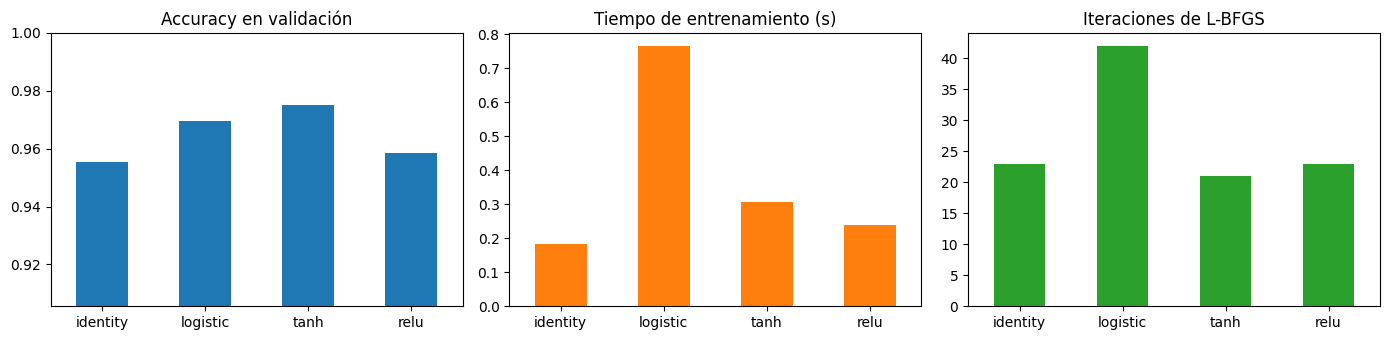

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
resultados["Accuracy"].plot.bar(ax=axes[0], color="tab:blue", rot=0)
axes[0].set_title("Accuracy en validación"); axes[0].set_ylim(resultados["Accuracy"].min() - 0.05, 1.0)
resultados["Segundos"].plot.bar(ax=axes[1], color="tab:orange", rot=0)
axes[1].set_title("Tiempo de entrenamiento (s)")
resultados["Iteraciones"].plot.bar(ax=axes[2], color="tab:green", rot=0)
axes[2].set_title("Iteraciones de L-BFGS")
for ax in axes: ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 8. Robustez: repetición con varias semillas
Un solo entrenamiento depende de la inicialización aleatoria y el tiempo medido varía entre ejecuciones. Para no concluir con una sola corrida, se repite el entrenamiento con **5 semillas** distintas (mismas particiones) y se resume la **media ± desviación estándar**. La prueba sigue sin usarse.

In [33]:
SEMILLAS = [0, 1, 2, 3, 4]
registros = []
for activacion in ["identity", "logistic", "tanh", "relu"]:
    for s in SEMILLAS:
        m = construir_mlp(activacion, semilla=s)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            t0 = time.perf_counter()
            m.fit(X_train, y_train)
            dt = time.perf_counter() - t0
        registros.append({"Activación": activacion, "Semilla": s,
                          "Accuracy val": accuracy_score(y_val, m.predict(X_val)),
                          "Segundos": dt,
                          "Iteraciones": m.named_steps["mlp"].n_iter_})

multi = pd.DataFrame(registros)
resumen = multi.groupby("Activación").agg(
    acc_media=("Accuracy val", "mean"), acc_std=("Accuracy val", "std"),
    seg_media=("Segundos", "mean"), seg_std=("Segundos", "std"),
    iter_media=("Iteraciones", "mean")).loc[["identity", "logistic", "tanh", "relu"]]
print(resumen.round(4).to_string())

            acc_media  acc_std  seg_media  seg_std  iter_media
Activación                                                    
identity       0.9539   0.0042     0.4631   0.4115        25.2
logistic       0.9733   0.0089     0.9171   0.6808        43.4
tanh           0.9717   0.0046     0.3128   0.0626        21.0
relu           0.9678   0.0091     0.2783   0.0751        23.6


## 9. Selección del modelo
La regla se fija **antes de mirar la prueba**, e incorpora el tiempo de entrenamiento como pide el enunciado:

1. Se toma la mejor accuracy media de validación (sección 8).
2. Se consideran *equivalentes en desempeño* las activaciones cuya accuracy media quede a **menos de 1 punto porcentual** de la mejor.
3. Entre las equivalentes se elige la de **menor tiempo medio de entrenamiento**.

In [34]:
mejor_acc = resumen["acc_media"].max()
equivalentes = resumen[resumen["acc_media"] >= mejor_acc - 0.01]
mejor_activacion = equivalentes["seg_media"].idxmin()

print(f"Mejor accuracy media de validación: {mejor_acc:.4f}")
print("Activaciones equivalentes (dentro de 1 pp):", list(equivalentes.index))
print("Activación seleccionada:", mejor_activacion)

Mejor accuracy media de validación: 0.9733
Activaciones equivalentes (dentro de 1 pp): ['logistic', 'tanh', 'relu']
Activación seleccionada: relu


## 10. Evaluación final en prueba
Se evalúa **solo** el modelo seleccionado (entrenado con el 60 % de entrenamiento, sin reajustarlo con validación) y la referencia sobre los mismos casos de prueba.

                        Accuracy  Balanced accuracy  F1 macro   Kappa  Log loss
Referencia mayoritaria    0.1000             0.1000    0.0182  0.0000   32.4393
MLP (relu)                0.9611             0.9608    0.9603  0.9568    0.2617


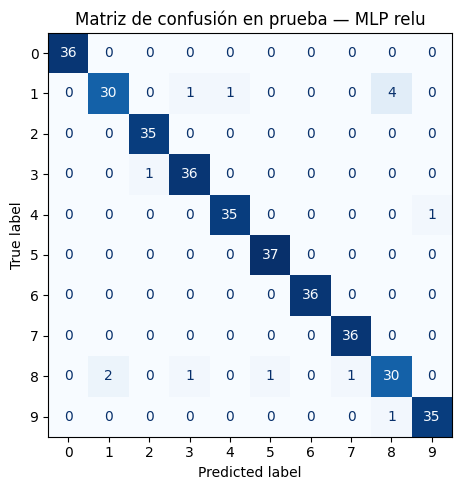

Informe por clase:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9375    0.8333    0.8824        36
           2     0.9722    1.0000    0.9859        35
           3     0.9474    0.9730    0.9600        37
           4     0.9722    0.9722    0.9722        36
           5     0.9737    1.0000    0.9867        37
           6     1.0000    1.0000    1.0000        36
           7     0.9730    1.0000    0.9863        36
           8     0.8571    0.8571    0.8571        35
           9     0.9722    0.9722    0.9722        36

    accuracy                         0.9611       360
   macro avg     0.9605    0.9608    0.9603       360
weighted avg     0.9608    0.9611    0.9606       360



In [35]:
mejor_modelo = modelos[mejor_activacion]
comparacion_test = pd.DataFrame({
    "Referencia mayoritaria": evaluar(referencia, X_test, y_test),
    f"MLP ({mejor_activacion})": evaluar(mejor_modelo, X_test, y_test),
}).T
print(comparacion_test.round(4).to_string())

y_pred = mejor_modelo.predict(X_test)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=range(10)),
                       display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión en prueba — MLP {mejor_activacion}")
plt.tight_layout()
plt.show()

print("Informe por clase:")
print(classification_report(y_test, y_pred, digits=4))

### 10.1 Ejemplos mal clasificados

Errores en prueba: 14 de 360


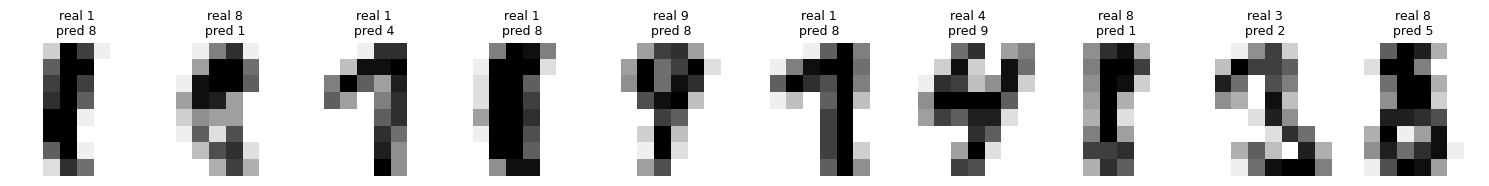

In [36]:
errores = np.flatnonzero(y_pred != y_test)
print(f"Errores en prueba: {len(errores)} de {len(y_test)}")
n = min(10, len(errores))
if n:
    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 2.2), squeeze=False)
    for ax, i in zip(axes[0], errores[:n]):
        ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"real {y_test[i]}\npred {y_pred[i]}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 11. Análisis de resultados y conclusión

**Desempeño.** Con la semilla 42 todas las activaciones alcanzan 100 % de accuracy en entrenamiento, así que la diferencia está en validación:

- **identity** es la que peor generaliza. Es lo esperado: sin no linealidad la red equivale a un modelo lineal, por muchas neuronas que tenga. Sus probabilidades son peores. Aun así rinde bien porque los dígitos son casi linealmente separables en 64 dimensiones.
- **logistic, tanh y relu** quedan muy cerca entre sí. Las diferencias son del orden de la desviación estándar entre semillas, así que **no se puede afirmar que una sea mejor que otra solo por precisión**.
- **Sobreajuste:** el 100 % en entrenamiento frente a ≈ 97 % en validación indica sobreajuste leve, normal con 64 entradas, 50 neuronas y pocas muestras.

**Tiempo de entrenamiento.** `logistic` es la más lenta, al saturar, sus gradientes son pequeños y L-BFGS necesita más pasos. `tanh` converge en menos iteraciones y resulta la más rápida, con `relu` e `identity` en un nivel similar. Los tiempos absolutos son de décimas de segundo, por lo que en este dataset la diferencia no es crítica; sí lo sería en problemas más grandes.

**Conclusión.** conviene usar **`tanh`**: está entre las mejores en validación y es la más rápida.